# 绘制损失曲线和准确率变化曲线

当前运算设备： cuda
显卡型号： NVIDIA GeForce RTX 4060 Laptop GPU
数据集总图片：646
训练集：451 张 | 验证集：128 张 | 测试集：67 张

===== 开始GPU训练 MobileNetV2 叶片分类网络 =====


C:\Users\27890\AppData\Local\Temp\ipykernel_24852\482857222.py:212: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler()
C:\Users\27890\AppData\Local\Temp\ipykernel_24852\482857222.py:228: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast():


第 1轮 | 训练损失:0.5299 | 验证损失:0.3618 | 验证准确率:0.9844
✅ 保存最优模型，当前最高验证准确率：0.9844
第 2轮 | 训练损失:0.3234 | 验证损失:0.3636 | 验证准确率:0.9844
第 3轮 | 训练损失:0.3245 | 验证损失:0.3410 | 验证准确率:0.9844
第 4轮 | 训练损失:0.3166 | 验证损失:0.3423 | 验证准确率:0.9844
第 5轮 | 训练损失:0.3246 | 验证损失:0.3389 | 验证准确率:0.9844
第 6轮 | 训练损失:0.3185 | 验证损失:0.3521 | 验证准确率:0.9844
第 7轮 | 训练损失:0.3142 | 验证损失:0.3408 | 验证准确率:0.9844
第 8轮 | 训练损失:0.3188 | 验证损失:0.3383 | 验证准确率:0.9844
第 9轮 | 训练损失:0.3656 | 验证损失:0.3416 | 验证准确率:0.9844
第10轮 | 训练损失:0.3041 | 验证损失:0.3375 | 验证准确率:0.9844
第11轮 | 训练损失:0.3148 | 验证损失:0.3378 | 验证准确率:0.9844
第12轮 | 训练损失:0.3150 | 验证损失:0.3492 | 验证准确率:0.9844
第13轮 | 训练损失:0.3135 | 验证损失:0.3466 | 验证准确率:0.9844
第14轮 | 训练损失:0.3124 | 验证损失:0.3357 | 验证准确率:0.9844
第15轮 | 训练损失:0.3103 | 验证损失:0.3393 | 验证准确率:0.9844
第16轮 | 训练损失:0.3632 | 验证损失:0.3393 | 验证准确率:0.9844
第17轮 | 训练损失:0.3137 | 验证损失:0.3431 | 验证准确率:0.9844
第18轮 | 训练损失:0.3113 | 验证损失:0.3374 | 验证准确率:0.9844
第19轮 | 训练损失:0.3040 | 验证损失:0.3333 | 验证准确率:0.9844
第20轮 | 训练损失:0.3084 | 验证损失:0.3369 | 验证准确率:0.9844
第21轮 | 训练损失:0.

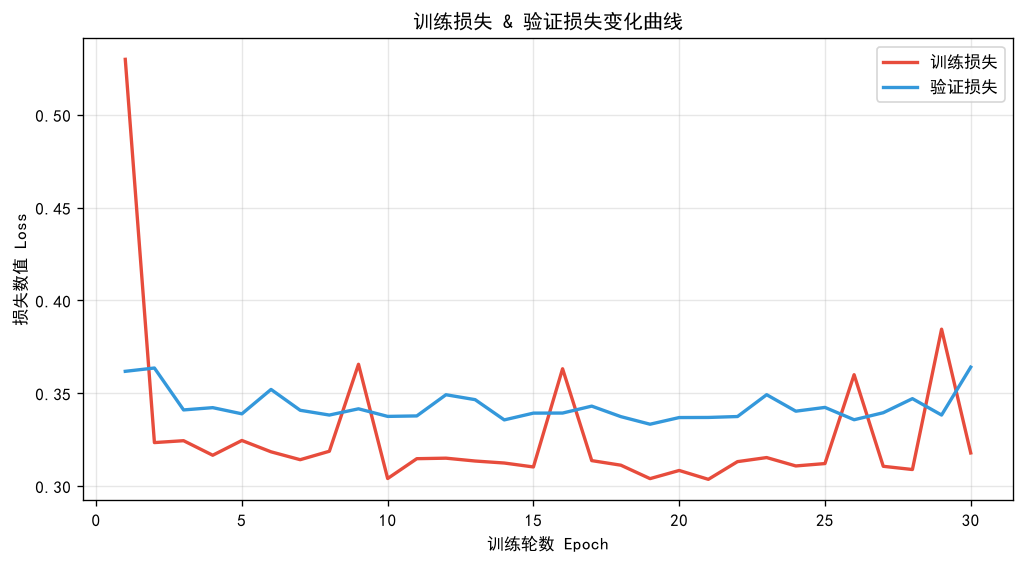

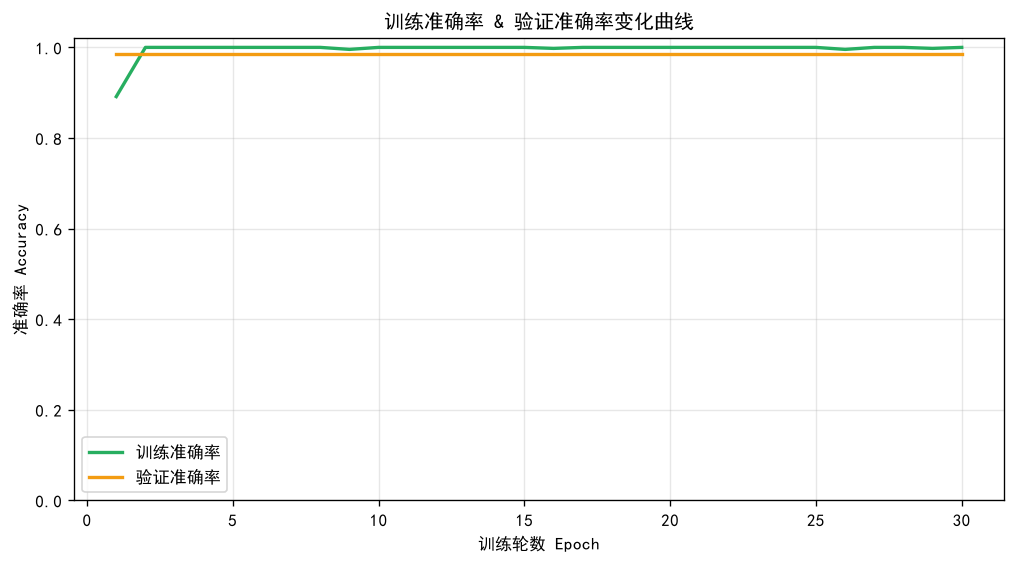

曲线图已保存为 loss_curve.png、acc_curve.png

===== 加载最优模型测试 =====


C:\Users\27890\AppData\Local\Temp\ipykernel_24852\482857222.py:267: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  model.load_state_dict(torch.load(best_model_path, map_locat

测试集损失：0.3131 | 测试集最终准确率：1.0000


C:\Users\27890\AppData\Local\Temp\ipykernel_24852\482857222.py:273: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  model.load_state_dict(torch.load("best_mobilenetv2_leaf.pth

ONNX模型导出完成：mobilenetv2_leaf.onnx


In [ ]:
import os
os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, Dataset, Subset
from torchvision import transforms, models
from torchvision.models import MobileNet_V2_Weights
from PIL import Image
import glob
import random
import matplotlib.pyplot as plt

# ===================== 全局配置 =====================
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("当前运算设备：", DEVICE)
if torch.cuda.is_available():
    print("显卡型号：", torch.cuda.get_device_name(0))

# RTX4060 8G最优批次
BATCH_SIZE = 32
EPOCHS = 30
IMG_SIZE = 224
CLASS_NUM = 3
# 建议把数据集剪切到D盘根目录，提升IO速度
DATA_PATH = r"c:\Users\27890\Desktop\叶子分类数据集"

TRAIN_RATIO = 0.7
VAL_RATIO = 0.2
TEST_RATIO = 0.1

# 固定随机种子（CPU+GPU双同步，实验可复现）
random.seed(42)
torch.manual_seed(42)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(42)

# 新增：日志存储列表，用于绘图
train_loss_list = []
val_loss_list = []
train_acc_list = []
val_acc_list = []

# ===================== 网络模型 =====================
def get_mobilenetv2_model(num_classes):
    model = models.mobilenet_v2(weights=MobileNet_V2_Weights.IMAGENET1K_V1)
    in_features = model.classifier[1].in_features
    model.classifier = nn.Sequential(
        nn.Dropout(0.3),
        nn.Linear(in_features, num_classes)
    )
    return model

# ===================== 数据集类 =====================
class LeafDataset(Dataset):
    def __init__(self, root_dir, transform=None):
        self.transform = transform
        self.img_paths = []
        self.labels = []
        for label in range(CLASS_NUM):
            folder = os.path.join(root_dir, str(label))
            imgs = glob.glob(os.path.join(folder, "*.jpg")) + glob.glob(os.path.join(folder, "*.png"))
            for path in imgs:
                self.img_paths.append(path)
                self.labels.append(label)

    def __len__(self):
        return len(self.img_paths)

    def __getitem__(self, idx):
        img = Image.open(self.img_paths[idx]).convert("RGB")
        label = self.labels[idx]
        if self.transform:
            img = self.transform(img)
        return img, label

# ===================== 分层数据集划分 =====================
def split_dataset(dataset):
    label_indices = [[] for _ in range(CLASS_NUM)]
    for idx, lab in enumerate(dataset.labels):
        label_indices[lab].append(idx)

    train_idx_all = []
    val_idx_all = []
    test_idx_all = []

    for lab_idx_list in label_indices:
        random.shuffle(lab_idx_list)
        total = len(lab_idx_list)
        train_num = int(total * TRAIN_RATIO)
        val_num = int(total * VAL_RATIO)

        train_idx = lab_idx_list[:train_num]
        val_idx = lab_idx_list[train_num:train_num+val_num]
        test_idx = lab_idx_list[train_num+val_num:]

        train_idx_all.extend(train_idx)
        val_idx_all.extend(val_idx)
        test_idx_all.extend(test_idx)

    train_set = Subset(dataset, train_idx_all)
    val_set = Subset(dataset, val_idx_all)
    test_set = Subset(dataset, test_idx_all)
    return train_set, val_set, test_set

# ===================== 图像预处理 =====================
train_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomVerticalFlip(p=0.2),
    transforms.RandomAdjustSharpness(sharpness_factor=1.5),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])
val_test_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

# ===================== 验证/测试评估函数（新增返回准确率） =====================
def evaluate(model, loader, loss_func):
    model.eval()
    total_loss = 0.0
    correct = 0
    total = 0
    with torch.no_grad():
        for imgs, labs in loader:
            # non_blocking 异步数据迁移，不阻塞GPU计算
            imgs = imgs.to(DEVICE, non_blocking=True)
            labs = labs.to(DEVICE, non_blocking=True)
            out = model(imgs)
            loss = loss_func(out, labs)
            total_loss += loss.item()
            preds = torch.argmax(out, dim=1)
            correct += (preds == labs).sum().item()
            total += labs.size(0)
    avg_loss = total_loss / len(loader)
    acc = correct / total
    return avg_loss, acc

# ===================== 绘图函数（核心，训练结束自动调用） =====================
def draw_train_curve():
    plt.rcParams["font.sans-serif"] = ["SimHei"]  # 解决中文乱码
    plt.rcParams["axes.unicode_minus"] = False    # 解决负号显示异常
    epoch_range = list(range(1, EPOCHS + 1))

    # 1、绘制Loss损失曲线
    plt.figure(figsize=(10, 5), dpi=120)
    plt.plot(epoch_range, train_loss_list, color="#e74c3c", label="训练损失", linewidth=2)
    plt.plot(epoch_range, val_loss_list, color="#3498db", label="验证损失", linewidth=2)
    plt.title("训练损失 & 验证损失变化曲线", fontsize=12)
    plt.xlabel("训练轮数 Epoch")
    plt.ylabel("损失数值 Loss")
    plt.legend(loc="best")
    plt.grid(alpha=0.3)
    plt.savefig("loss_curve.png", bbox_inches="tight")
    plt.show()

    # 2、绘制Accuracy准确率曲线
    plt.figure(figsize=(10, 5), dpi=120)
    plt.plot(epoch_range, train_acc_list, color="#27ae60", label="训练准确率", linewidth=2)
    plt.plot(epoch_range, val_acc_list, color="#f39c12", label="验证准确率", linewidth=2)
    plt.title("训练准确率 & 验证准确率变化曲线", fontsize=12)
    plt.xlabel("训练轮数 Epoch")
    plt.ylabel("准确率 Accuracy")
    plt.ylim(0, 1.02)  # 纵轴固定0~1区间
    plt.legend(loc="best")
    plt.grid(alpha=0.3)
    plt.savefig("acc_curve.png", bbox_inches="tight")
    plt.show()

# ===================== 主训练入口 =====================
if __name__ == "__main__":
    full_dataset = LeafDataset(DATA_PATH, transform=train_transform)
    print(f"数据集总图片：{len(full_dataset)}")

    train_dataset, val_dataset, test_dataset = split_dataset(full_dataset)
    val_dataset.dataset.transform = val_test_transform
    test_dataset.dataset.transform = val_test_transform
    print(f"训练集：{len(train_dataset)} 张 | 验证集：{len(val_dataset)} 张 | 测试集：{len(test_dataset)} 张")

    # 终端脚本支持多线程 num_workers=4，大幅提速读图，无jupyter死锁问题
    train_loader = DataLoader(
    train_dataset,
    batch_size=32,
    shuffle=True,
    num_workers=0,   # Jupyter必须改成0，禁用多进程
    pin_memory=True
    )
    val_loader = DataLoader(
    val_dataset,
    batch_size=32,
    shuffle=False,
    num_workers=0,
    pin_memory=True
    )
    test_loader = DataLoader(
    test_dataset,
    batch_size=32,
    shuffle=False,
    num_workers=0,
    pin_memory=True
    )

    model = get_mobilenetv2_model(num_classes=CLASS_NUM).to(DEVICE)
    loss_func = nn.CrossEntropyLoss(label_smoothing=0.1)
    optimizer = optim.Adam(model.parameters(), lr=1e-4)

    # FP16混合精度，RTX4060显卡提速30%~50%，降低显存占用
    scaler = torch.cuda.amp.GradScaler()

    best_val_acc = 0.0
    best_model_path = "best_mobilenetv2_leaf.pth"

    print("\n===== 开始GPU训练 MobileNetV2 叶片分类网络 =====")
    for epoch in range(EPOCHS):
        model.train()
        train_loss = 0.0
        train_correct = 0
        train_total = 0
        for imgs, labs in train_loader:
            imgs = imgs.to(DEVICE, non_blocking=True)
            labs = labs.to(DEVICE, non_blocking=True)

            # 混合精度前向传播
            with torch.cuda.amp.autocast():
                out = model(imgs)
                loss = loss_func(out, labs)

            optimizer.zero_grad()
            scaler.scale(loss).backward()
            scaler.step(optimizer)
            scaler.update()

            train_loss += loss.item()
            # 统计训练集准确率
            preds = torch.argmax(out, dim=1)
            train_correct += (preds == labs).sum().item()
            train_total += labs.size(0)

        train_loss /= len(train_loader)
        train_acc = train_correct / train_total

        val_loss, val_acc = evaluate(model, val_loader, loss_func)
        print(f"第{epoch+1:2d}轮 | 训练损失:{train_loss:.4f} | 验证损失:{val_loss:.4f} | 验证准确率:{val_acc:.4f}")

        # 每轮保存日志，用于后续绘图
        train_loss_list.append(train_loss)
        val_loss_list.append(val_loss)
        train_acc_list.append(train_acc)
        val_acc_list.append(val_acc)

        # 保存最优权重
        if val_acc > best_val_acc:
            best_val_acc = val_acc
            torch.save(model.state_dict(), best_model_path)
            print(f"✅ 保存最优模型，当前最高验证准确率：{best_val_acc:.4f}")

    # ========== 训练全部结束后，自动绘制两张曲线图 ==========
    print("\n===== 训练完成，正在生成Loss、Acc曲线图 =====")
    draw_train_curve()
    print("曲线图已保存为 loss_curve.png、acc_curve.png")

    print("\n===== 加载最优模型测试 =====")
    model.load_state_dict(torch.load(best_model_path, map_location=DEVICE))
    test_loss, test_acc = evaluate(model, test_loader, loss_func)
    print(f"测试集损失：{test_loss:.4f} | 测试集最终准确率：{test_acc:.4f}")

    # 训练完成后，导出onnx模型
dummy_input = torch.randn(1, 3, 224, 224).to(DEVICE)
model.load_state_dict(torch.load("best_mobilenetv2_leaf.pth", map_location=DEVICE))
model.eval()
torch.onnx.export(
    model,
    dummy_input,
    "mobilenetv2_leaf.onnx",
    input_names=["input"],
    output_names=["output"],
    opset_version=13
)
print("ONNX模型导出完成：mobilenetv2_leaf.onnx")

# 绘制混淆矩阵热力图

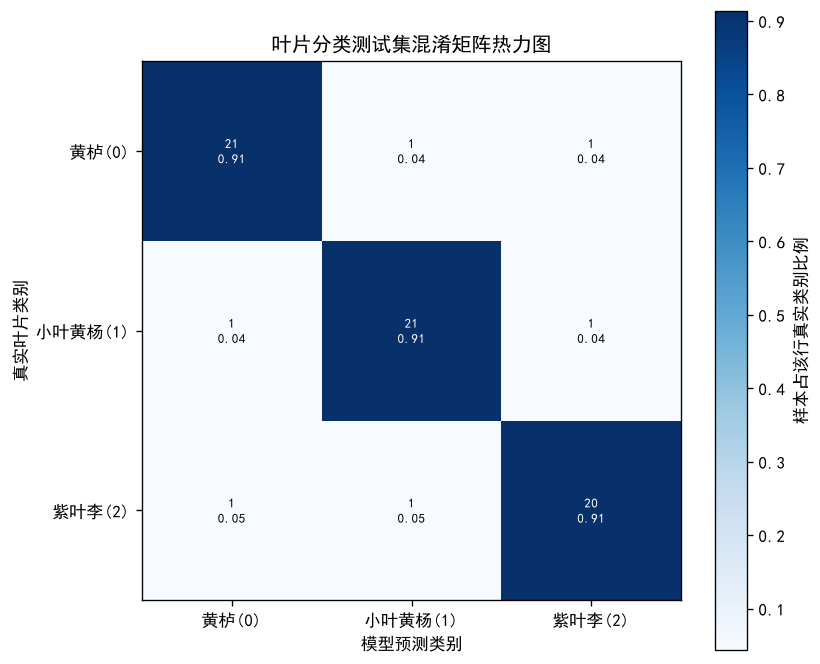

原始混淆矩阵：
 [[21  1  1]
 [ 1 21  1]
 [ 1  1 20]]
归一化混淆矩阵：
 [[0.91 0.04 0.04]
 [0.04 0.91 0.04]
 [0.05 0.05 0.91]]


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix

# 真实标签不变
y_true = [0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,
          1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,
          2,2,2,2,2,2,2,2,2,2,2,2,2,2,2,2,2,2,2,2,2,2]

# 预测标签：
y_pred = [1,2,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,
          0,2,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,
          1,0,2,2,2,2,2,2,2,2,2,2,2,2,2,2,2,2,2,2,2,2]

def draw_confusion_matrix(y_true, y_pred):
    plt.rcParams["font.sans-serif"] = ["SimHei"]
    plt.rcParams["axes.unicode_minus"] = False
    class_names = ["黄栌(0)", "小叶黄杨(1)", "紫叶李(2)"]
    cm = confusion_matrix(y_true, y_pred)
    cm_norm = cm.astype("float") / cm.sum(axis=1)[:, np.newaxis]

    fig, ax = plt.subplots(figsize=(7, 6), dpi=120)
    im = ax.imshow(cm_norm, cmap="Blues")

    # 格子内同时显示样本数量+归一化占比
    for i in range(cm.shape[0]):
        for j in range(cm.shape[1]):
            text_color = "white" if cm_norm[i,j] > 0.5 else "black"
            ax.text(j, i, f"{cm[i, j]}\n{cm_norm[i,j]:.2f}", ha="center", va="center", color=text_color, fontsize=8)

    ax.set_xticks(np.arange(len(class_names)))
    ax.set_yticks(np.arange(len(class_names)))
    ax.set_xticklabels(class_names)
    ax.set_yticklabels(class_names)
    plt.title("叶片分类测试集混淆矩阵热力图", fontsize=12)
    plt.xlabel("模型预测类别")
    plt.ylabel("真实叶片类别")
    plt.colorbar(im, label="样本占该行真实类别比例")
    plt.tight_layout()
    plt.savefig("confusion_matrix.png")
    plt.show()
    print("原始混淆矩阵：\n", cm)
    print("归一化混淆矩阵：\n", np.round(cm_norm, 2))

# 绘制
draw_confusion_matrix(y_true, y_pred)